# Which changes improve the full pricing policy?

The original neural policy mostly charges 90 across a 330-day selling period that starts with 10 rooms. A better rule must balance selling before arrival against retaining scarce rooms for later sales.

This notebook tests data and training changes, then asks whether the complete policy improves. The selected combination raises revenue by about 1.6%, recovering 36% of the original gap to the simulator optimum. Most improvement occurs near the deadline; earlier inventory-sensitive decisions remain weak.

**Words used in this notebook**

- **Policy:** a rule for choosing a price from days and rooms remaining.
- **Q score:** the model's estimate of revenue from a price, including future sales.
- **CQL:** Conservative Q-Learning, the method that fits this neural model from saved decisions and outcomes. It discourages overly optimistic scores relative to recorded actions.
- **Margin:** one Q score minus another. A negative `Q(55) − Q(90)` favors 90 over 55.
- **Planner:** a separate method that estimates sale probabilities and calculates a pricing rule using known inventory dynamics.


In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'hotel_pricing').is_dir() and (p / 'configs/environment.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the hotel-pricing repository.')
sys.path.insert(0, str(ROOT))
from scripts.policy_improvement.presentation import (MODEL_NAMES, LEGACY_NAMES, EPISODE_NAMES, REVISED_DEFINITION,
    case_label, case_table, regional_table, policy_maps)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 100)
def required(path):
    if not path.is_file():
        raise FileNotFoundError(f'Required saved evidence is missing: {path}. See README.md.')
    return path
def figure(name):
    path = OUT / 'figures' / f'{name}.png'
    if path.is_file(): display(Image(filename=str(path), width=1000))
    else: print(f'Optional display image unavailable: {path.name}; numerical evidence remains required.')

OUT=ROOT/'outputs/policy_improvement/training'
from scripts.policy_improvement.presentation import EVIDENCE, FIGURES, DERIVED
FINAL=DERIVED
def read(name): return json.loads(required(OUT/name).read_text())
def final_figure(name): display(Image(filename=str(required(FIGURES/f'{name}.png')),width=1050))
results=pd.DataFrame(read('results.json'))
confirmation=results[results.stage=='confirmation']
assert len(confirmation)==12,'Required confirmation checkpoints are missing.'
cases=pd.DataFrame(json.loads(required(FINAL/'confirmation_cases.json').read_text()))

cases['configuration']=cases.configuration.replace(LEGACY_NAMES)

## 1. How much can be achieved with the original data?

A separate planner pools offers by price, estimates sale probabilities, and calculates a policy using known inventory dynamics. It accounts for future selling opportunities and nearly reaches the optimum without new samples.

**Takeaway: useful information already exists; the neural policy does not use it as effectively as this structured method.**

This is an achievable reference point under stationary, price-only demand, not a general guarantee or an explanation of the neural network.


In [2]:
demand=read('diagnostics/learned_demand.json')
display(pd.DataFrame(demand['counts_and_probabilities'])[['action','trials','sales','sale_probability']].assign(price=[55,70,90,110,125]).drop(columns='action'))
display(pd.DataFrame({'policy':[MODEL_NAMES['CONF_U20'],MODEL_NAMES['planner'],MODEL_NAMES['optimal']],
 'episode_revenue':[results[results.experiment_id=='E1_U20'].exact_revenue.mean(),demand['exact_revenue'],demand['exact_revenue']+demand['oracle_gap']]}))

,trials,sales,sale_probability,price
0,32492,4931,0.151760,55
1,48749,4103,0.084166,70
2,162057,5820,0.035913,90
3,48427,759,0.015673,110
4,32535,274,0.008422,125


,policy,episode_revenue
0,Baseline model,851.003070
1,Planner fitted to the original data,888.373761
2,Best possible in this simulator,888.410341


## 2. Can a compact diagnostic rule out a simple learning defect?

The final day removes future revenue. With one day and one room, 55 earns 8.342 in expectation and 90 earns 3.273. Implausibly high model scores prompted checks of inputs, price indexing, reward units, and episode endings. No defect was found in those tested mechanics.

The first table checks that even an enormous next-state estimate cannot enter the final-day training target. Original local records are sparse: three offers at 55 produced no sale. With many independent observations at each price, direct fitting and minibatch training both choose 55.

**This diagnostic supports investigating data and learning; it does not establish competence across the full task.**


In [3]:
audit=read('diagnostics/pipeline_audit.json')
display(pd.DataFrame(audit['numerical_targets']))
logged=read('diagnostics/terminal_logged_fits.json')
display(pd.DataFrame(next(x for x in logged if x['subset']=='state_1_1')['counts']).assign(price=[55,70,90,110,125])[['price','trials','sales']])
positive=read('diagnostics/terminal_positive_control.json')
display(pd.DataFrame([{'penalty_weight':p['alpha'],'direct_fit_passes':p['deterministic_pass'],
 'minibatch_selected_price':[55,70,90,110,125][int(np.argmax(p['minibatch_q']))]} for p in positive]))

,case,state,action,raw_reward,scaled_reward,next_state,terminated,target_with_next_q_1e6
0,last_day_sale,"[1, 3]",0,55.0,0.611111,"[0, 2]",True,0.611111
1,last_day_no_sale,"[1, 1]",3,0.0,0.000000,"[0, 1]",True,0.000000
2,early_sellout,"[53, 1]",0,55.0,0.611111,"[52, 0]",True,0.611111
3,continuing,"[330, 10]",3,0.0,0.000000,"[329, 10]",False,1000000.000000


,price,trials,sales
0,55,3,0
1,70,3,0
2,90,21,1
3,110,4,0
4,125,6,0


,penalty_weight,direct_fit_passes,minibatch_selected_price
0,0.0,True,55
1,0.1,True,55


## 3. Which changes were tested?

| Approach | Adds new data? | Needs new simulator samples? | Changes neural-network training? |
| --- | --- | --- | --- |
| Late-window replay | No | No | Yes: repeat existing late-window records more often |
| Balanced probes | Yes | Yes | Yes: train on the augmented dataset |
| Learned-demand planner | No | No | No: build a separate policy |

The planner uses known inventory rules. All finished policies use the simulator for evaluation. “Needs new simulator samples” refers to collection, not evaluation.

The study first tried replay and longer training. They changed scores but barely improved revenue. Balanced probes then supplied 150,000 fresh outcomes across the final 30 days. Both sales and no-sales were kept.

**Collection was active and targeted. Training began afterward on a frozen dataset.** The fitting stage remained offline: the learner did not ask the simulator for new outcomes while fitting.


In [4]:
development=results[results.stage=='development']
labels={'E1_U20':MODEL_NAMES['CONF_U20'],'E1_U100':MODEL_NAMES['CONF_U100'],
'E1_R20':'Late replay, 20k','E1_R100':'Late replay, 100k',
'E2_familiar100':'Fresh familiar probes','E2_balanced100':'Balanced probes',
'E3_method100':'Balanced probes + log-time input'}
dev=development[['experiment_id','seed','exact_revenue']].copy()
dev['approach']=dev.experiment_id.map(labels)
display(dev.pivot(index='approach',columns='seed',values='exact_revenue').reindex(list(labels.values())).rename_axis(columns='Training seed'))

Training seed,0,1
approach,,
Baseline model,851.003070,851.003070
Baseline with longer training,851.003070,851.003070
"Late replay, 20k",851.068935,851.007705
"Late replay, 100k",851.003238,851.226111
Fresh familiar probes,852.950416,851.336194
Balanced probes,854.232201,854.218125
Balanced probes + log-time input,861.359703,859.940380


## 4. Did the improvement repeat in a fresh check?

Balanced data helped in development. Giving the network more resolution near the deadline with a logarithmic time input helped further. The study fixed this complete configuration before testing it again.

The fresh check uses a newly collected balanced dataset and three unused training seeds. A seed changes starting weights and sampled batches. The table keeps each result visible.

A matched **control** changes only one part: it keeps the usual linear time input. This checks whether the logarithmic input adds a repeatable benefit.

**Takeaway: the revised model improves in all three seeds, but the revised model with the original time scale does at least as well on average.**


**Revised model:** targeted additional observations, more attention to late-period records, logarithmic time input, and 100,000 updates. **Baseline model:** original data and setup, with 20,000 updates. The longer-training baseline uses 100,000.

“Original time scale” means a linear representation of the time input. This comparison still uses a neural network, not linear regression. Each dot shows one seed’s result at the stated training endpoint. Short horizontal bars show the mean across the three seeds. The longer-training baseline continues the corresponding 20,000-update run. Both revised conditions share one new dataset across the three seeds.

policy,Baseline model,Baseline with longer training,Revised model,Revised model: original time scale
seed,,,,
10,851.00307,851.003968,866.367381,867.757344
11,851.00307,851.003070,869.805730,869.244643
12,851.00307,851.003304,857.233993,861.029090


Revenue gain: 1.58%. Share of original gap closed: 36%.


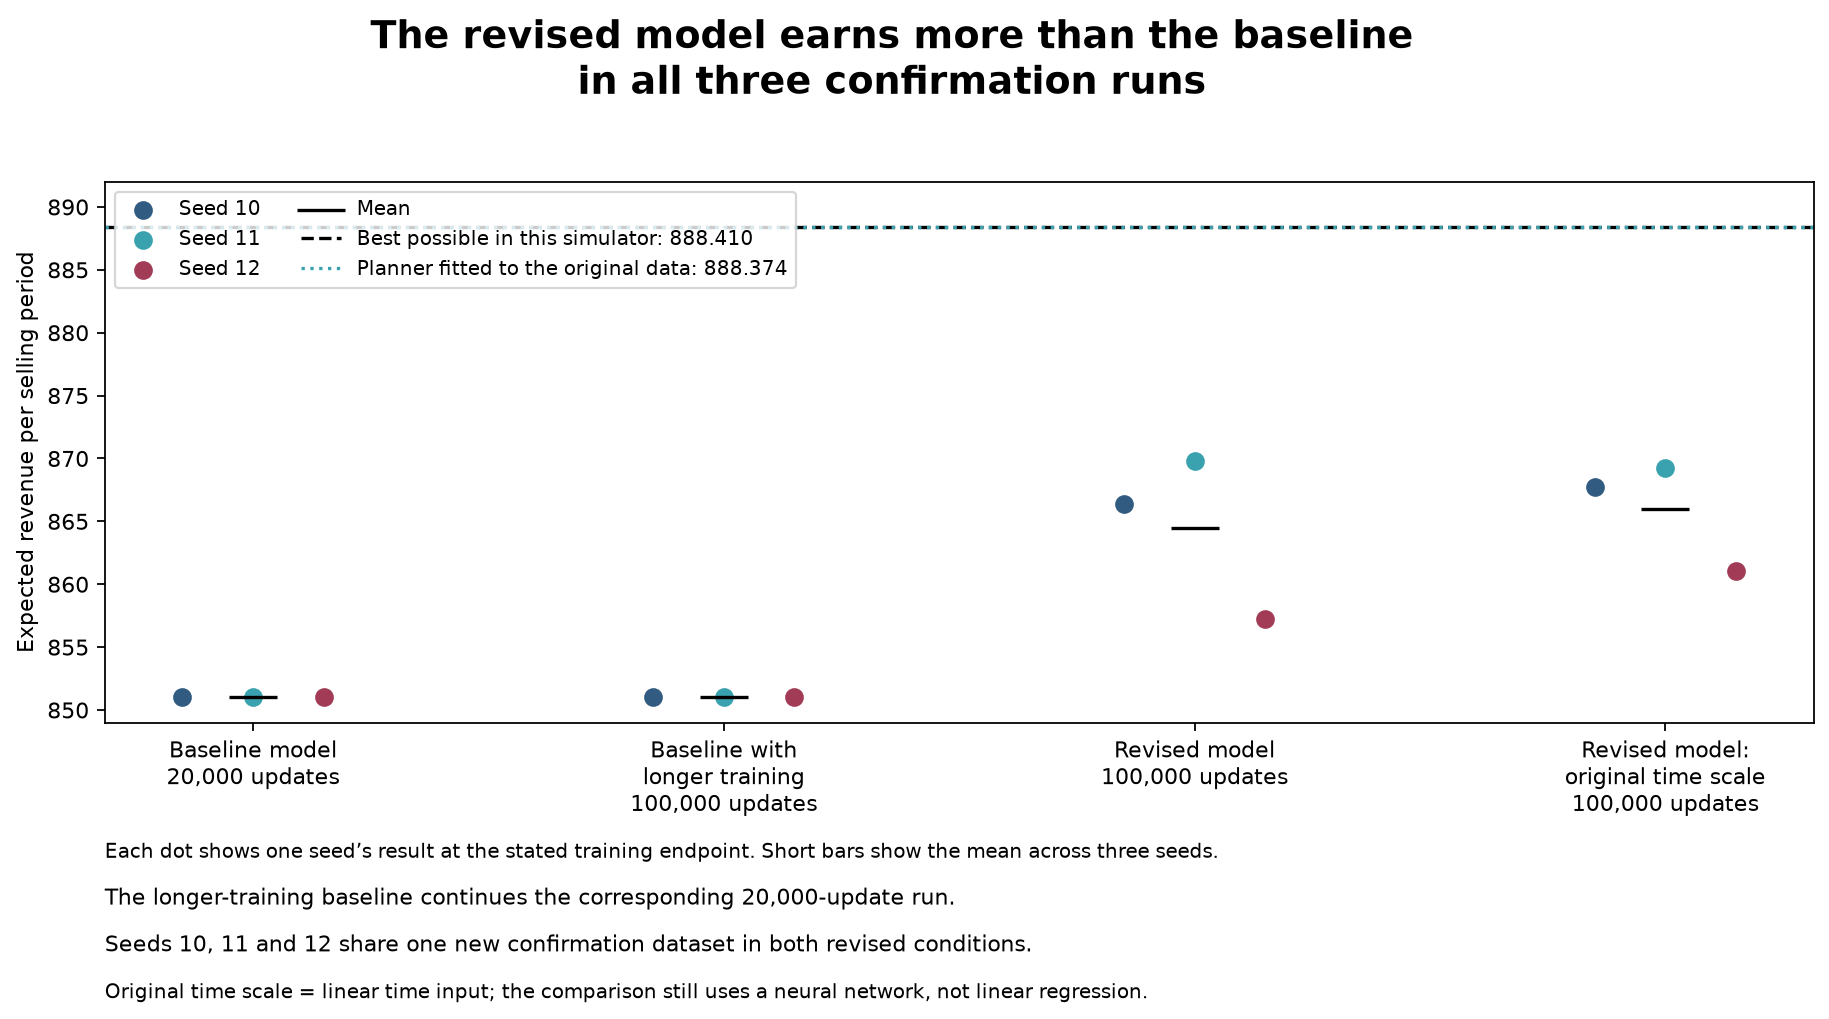

In [5]:
names={k:MODEL_NAMES[k] for k in ['CONF_U20','CONF_U100','CONF_C100','CONF_L100']}
shown=confirmation[['experiment_id','seed','exact_revenue']].copy()
shown['policy']=shown.experiment_id.map(names)
display(shown.pivot(index='seed',columns='policy',values='exact_revenue').reindex(columns=list(names.values())))
summary=json.loads(required(EVIDENCE/'final_summary.json').read_text())
print(f"Revenue gain: {summary['relative_gain_percent']:.2f}%. Share of original gap closed: {summary['gap_recovery_percent']:.0f}%.")
final_figure('confirmation_revenue')

The revenue increase from about 851 to 864 is 1.58%. Against an optimum of about 888, this closes 36% of the original shortfall. These percentages have different denominators.

## 5. Where did decisions improve, and where do weaknesses remain?

Four fixed cases illustrate the whole task. They are not a trajectory or a representative sample. The 200-day pair holds time fixed: the optimum charges 90 with 10 rooms but 125 with only two. All three revised models still charge 90 in both situations.

At 50 days and 10 rooms, discounting matters before the terminal boundary, but revised-model choices differ across seeds. Seed 12 misses the last-day decision yet earns 6.231 more over the full period. That single decision cannot be the acceptance test.


,Situation,Best possible in this simulator,Baseline model (all seeds),Revised model (seed 10),Revised model (seed 11),Revised model (seed 12)
0,"A — More time, many rooms: 200 days, 10 rooms",90,90,90,90,90
1,"B — More time, few rooms: 200 days, 2 rooms",125,90,90,90,90
2,"C — Less time, many rooms: 50 days, 10 rooms",55,90,90,55,70
3,"D — Last day, one room: 1 day, 1 room",55,90,55,55,90


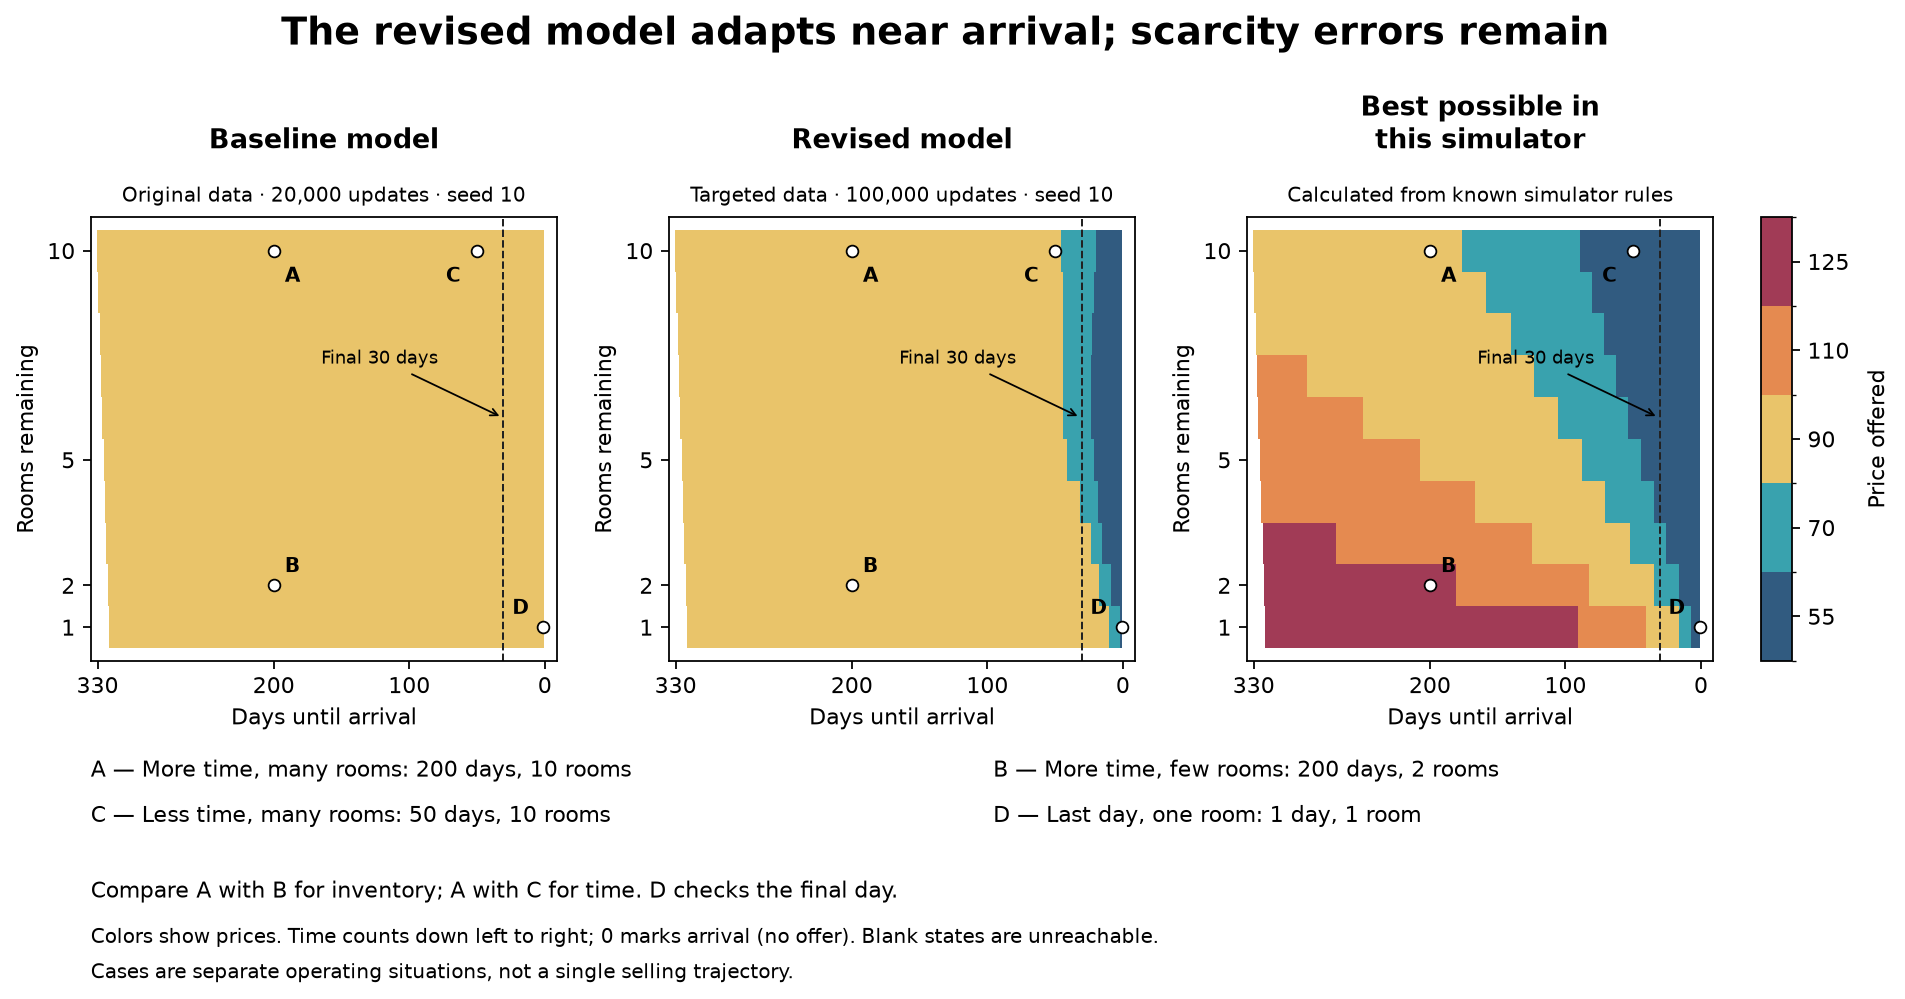

In [6]:
display(case_table(summary['illustrative_cases']))
final_figure('policy_maps')

### Is improvement concentrated near the deadline?

**Common-reference regret** measures losses from decisions using the same fixed-90 visitation weights for all policies. It locates weaknesses without changing the weighting of situations.

**Takeaway: this measure falls about 73% in the final 30 days, but only 5.7% earlier.** The revised model's regional values are not its own revenue-gap components and must not be added as its actual gap.


In [7]:
display(regional_table(summary['regional_comparison']).round(3))

,Region,Baseline model,Revised model (mean),Reduction (%)
0,Final 30 days,17.435,4.703,73.027
1,Earlier days,19.972,18.827,5.735


### How do time and inventory change recommendations?

The time-response curves compare baseline and revised models (seed 10) on shared axes. They show more discounting near the deadline. Inventory-response curves then hold days fixed for revised-model seed 10.

**Takeaway: scores can respond to inventory without changing the selected price.** A flat price curve does not mean the network ignores an input. Earlier scarcity decisions remain weak.


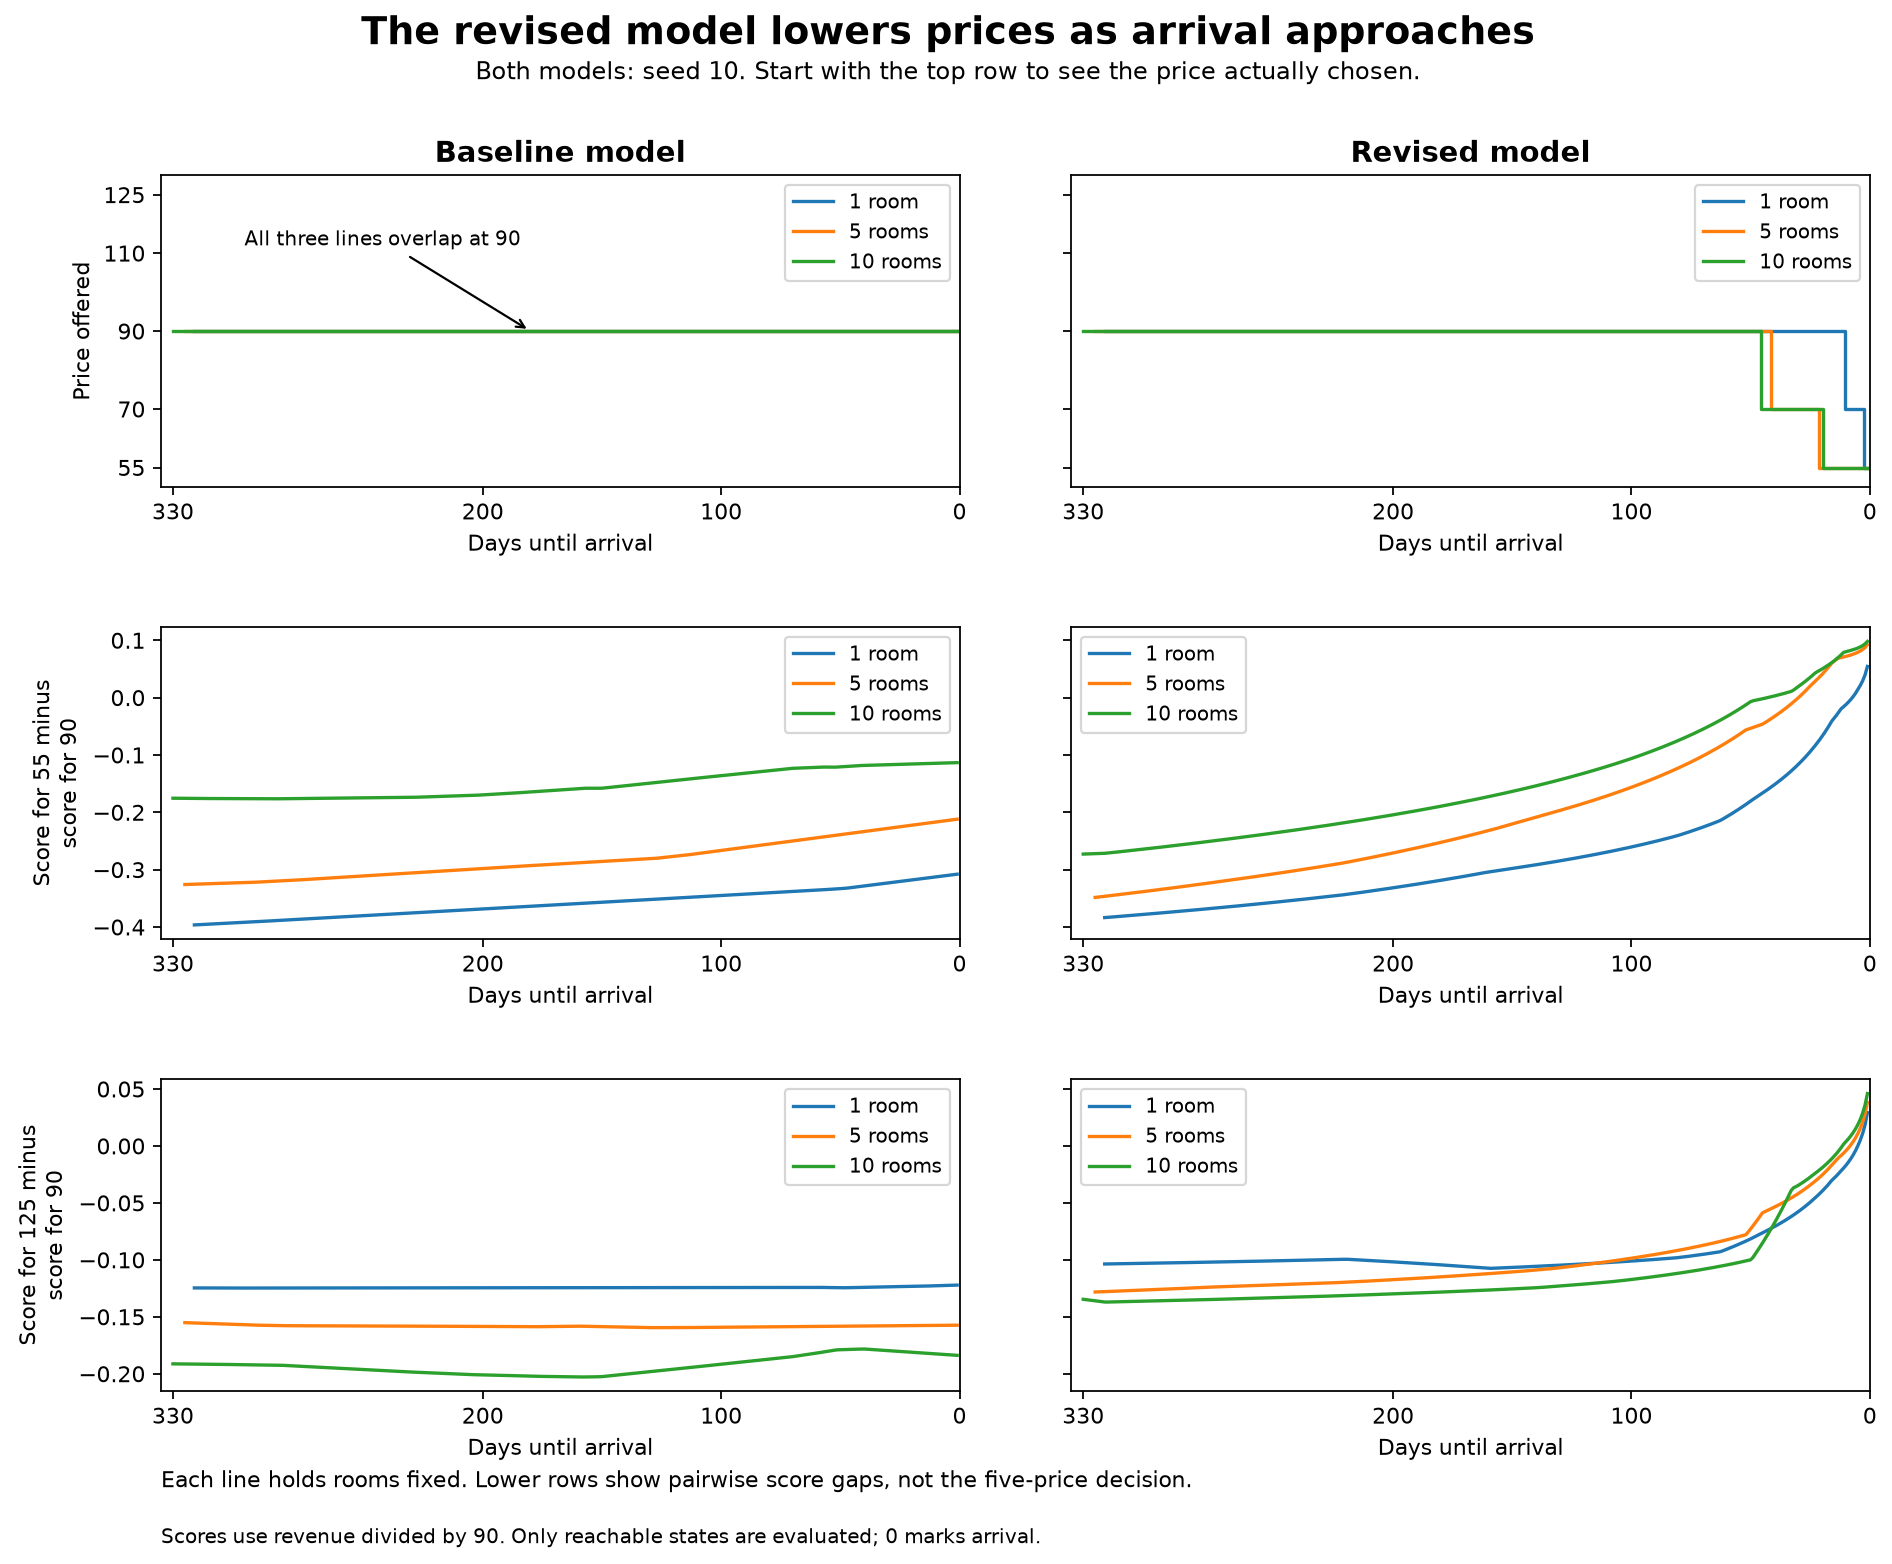

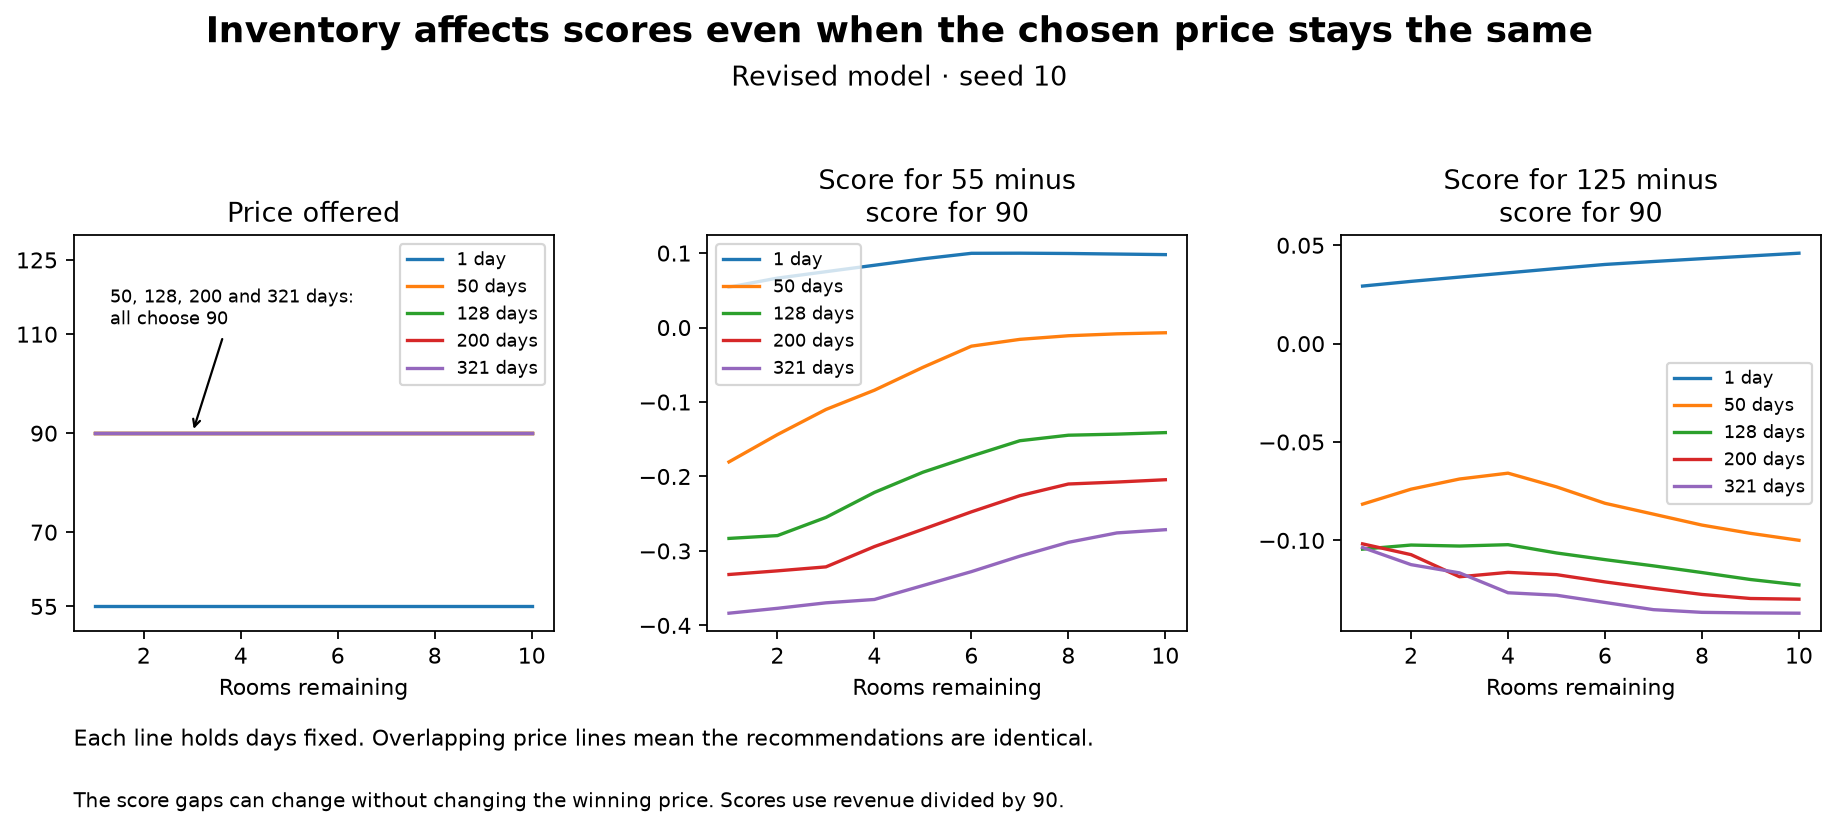

In [8]:
final_figure('time_responses')
final_figure('inventory_responses')

## 6. How did the model's price preferences change?

**Shapley attribution** splits a pairwise score margin relative to reference situations:

`reference margin + time contribution + inventory contribution = current margin`

For discounting, inspect `Q(55) − Q(90)` at one day and one room. In revised-model seed 10, the time contribution offsets the negative reference and inventory contributions. The positive margin favors 55. In seed 12, the margin stays negative and 90 remains the choice.

For scarcity, inspect `Q(125) − Q(90)` at 200 days and two rooms. The illustrated baseline and revised models still prefer 90, although the simulator optimum charges 125. Evaluating this earlier decision must include future sales; same-day revenue alone misses the opportunity cost of scarce inventory.

**The bars explain model preferences, not actual revenue or causal effects.** Scores use revenue divided by 90. All five scores determine the final choice.


Read the outlined final bar as the **sum of the first three**, not another input. A positive contribution pushes toward the alternative price. A positive final gap means it outranks 90; it need not outrank all five prices.

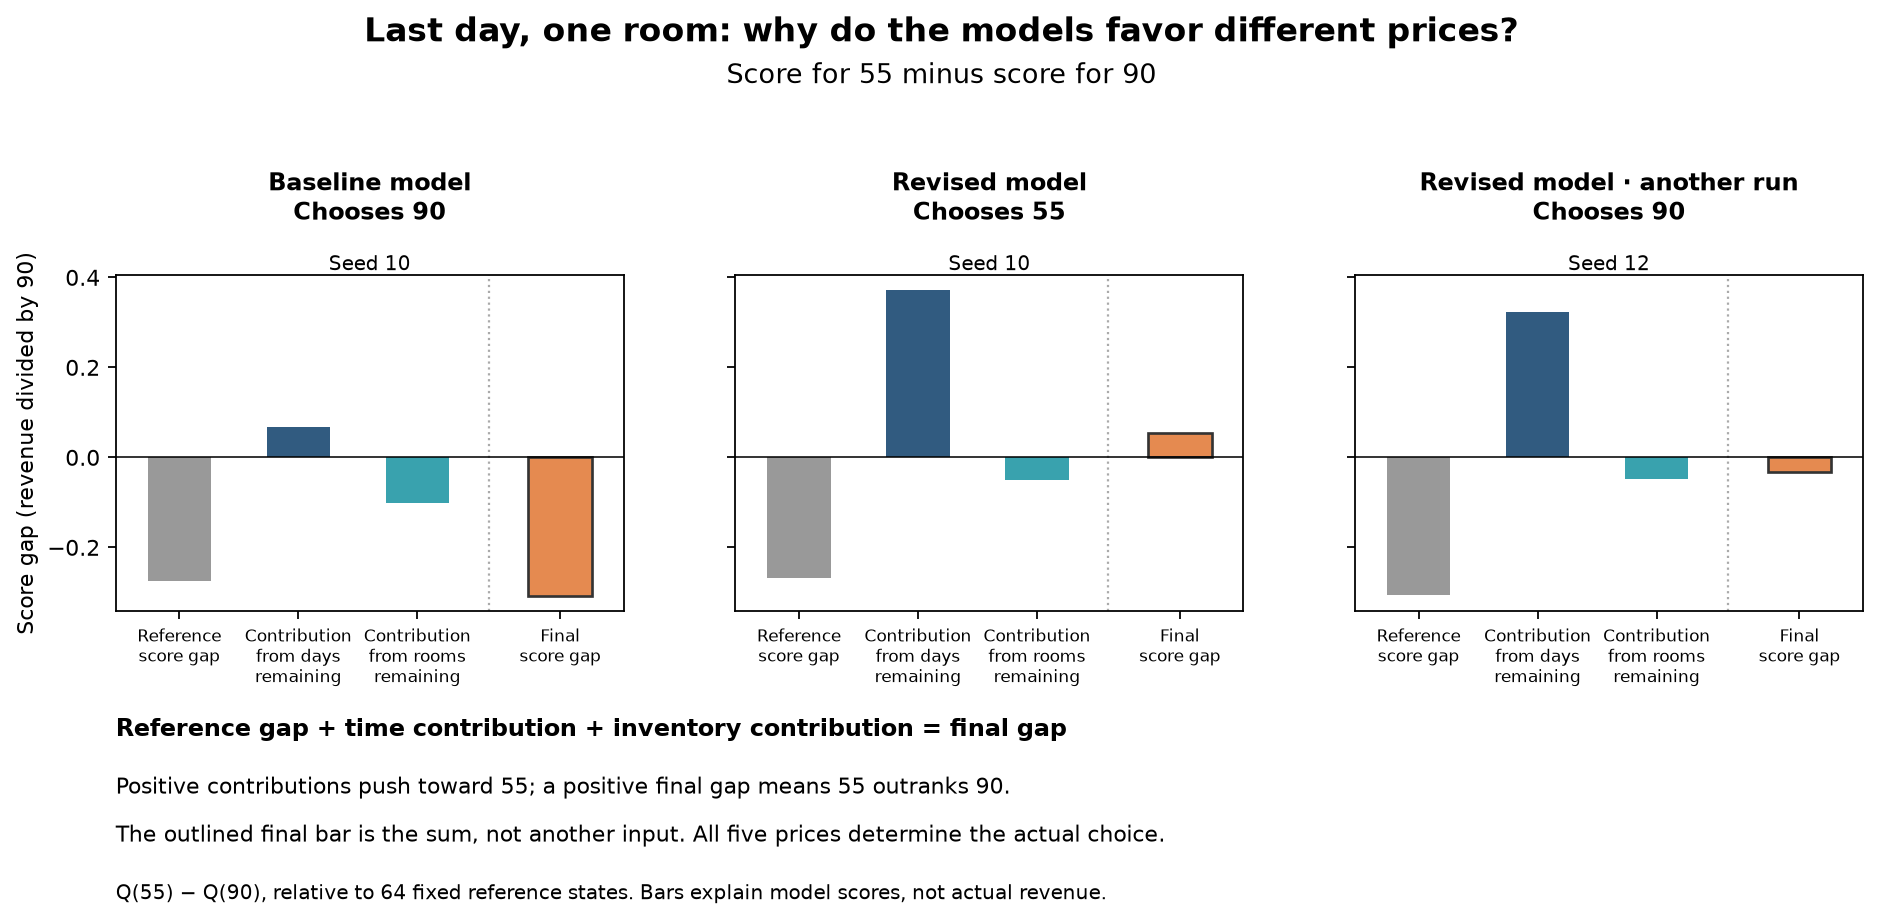

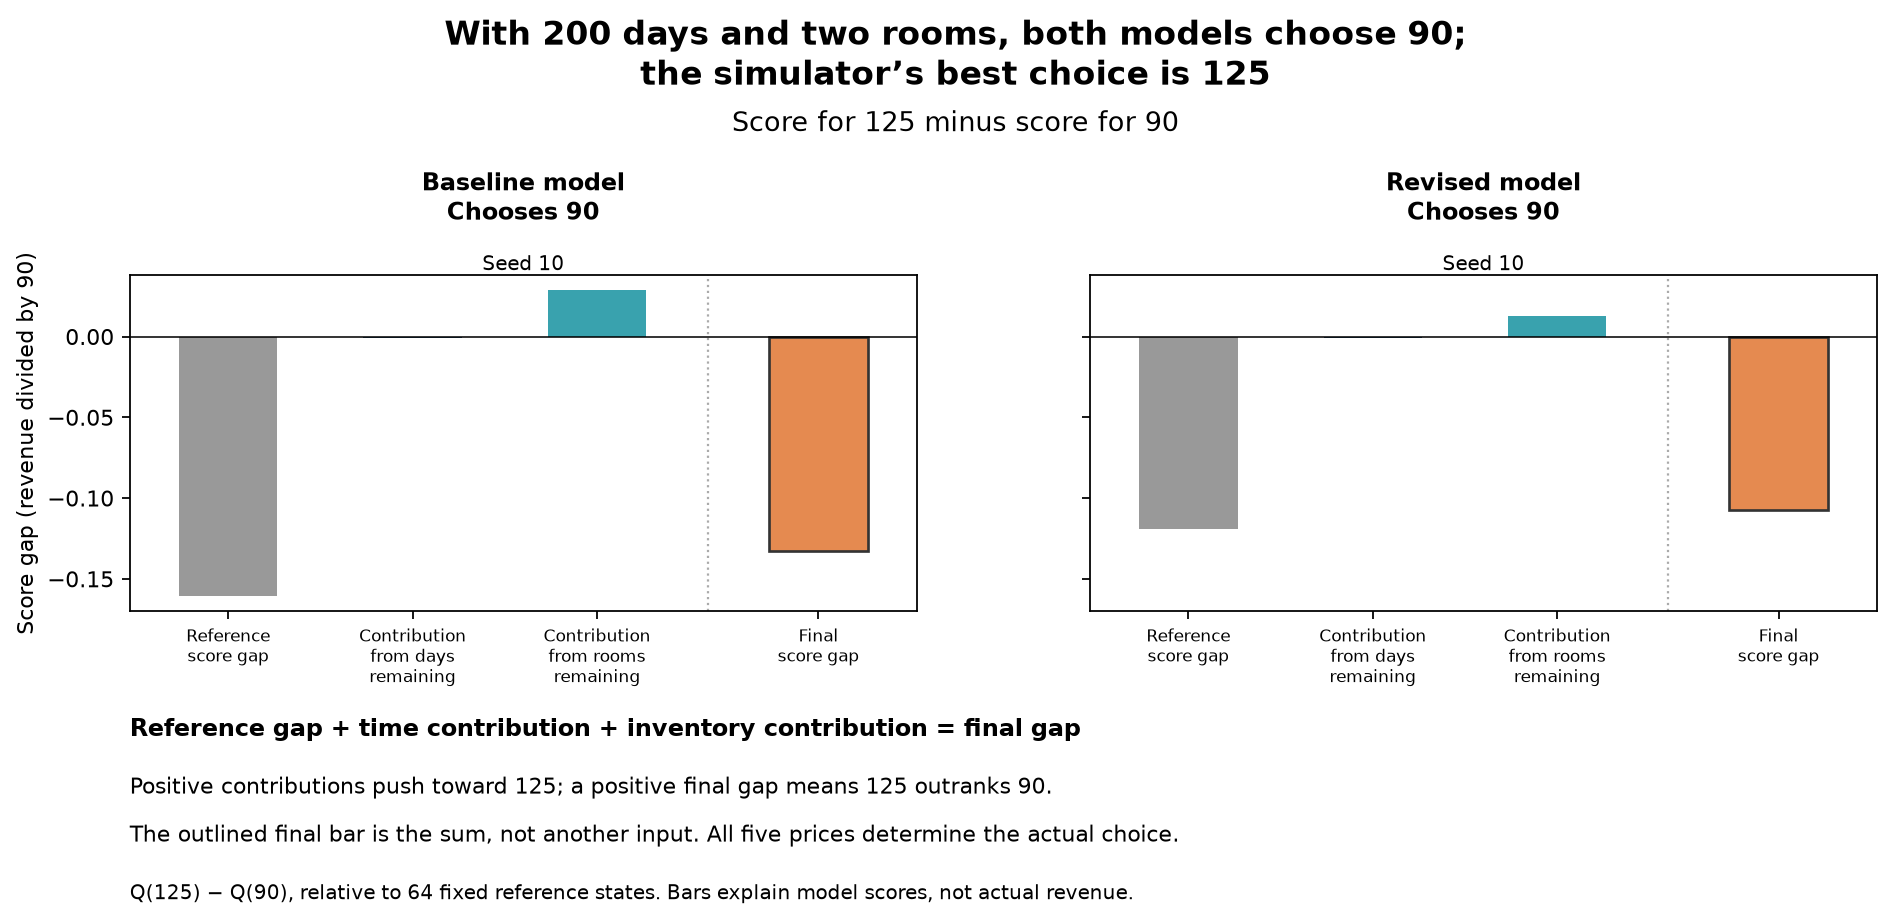

,configuration,seed,selected_price,margin,reference_base,time_contribution,inventory_contribution
6,Revised model,10,90,-0.107257,-0.119234,-0.000785,0.012763
18,Revised model,11,90,-0.104247,-0.107628,0.000681,0.002700
30,Revised model,12,90,-0.150407,-0.138533,-0.001996,-0.009878
42,Revised model: original time scale,10,90,-0.110554,-0.130122,-0.001634,0.021202
54,Revised model: original time scale,11,90,-0.115387,-0.110575,-0.008529,0.003717
66,Revised model: original time scale,12,90,-0.132658,-0.128528,-0.002094,-0.002036
78,Baseline with longer training,10,90,-0.096085,-0.098296,-0.002376,0.004587
90,Baseline model,10,90,-0.132811,-0.160567,-0.000761,0.028518
102,Baseline with longer training,11,90,-0.136435,-0.125780,-0.004861,-0.005794
114,Baseline model,11,90,-0.143987,-0.158189,-0.001170,0.015371


In [9]:
deadline=cases[(cases.days==1)&(cases.rooms==1)&(cases.contrast=='55-90')]
final_figure('deadline_explanation')
scarcity=cases[(cases.days==200)&(cases.rooms==2)&(cases.contrast=='125-90')]
final_figure('scarcity_explanation')
display(scarcity[['configuration','seed','selected_price','margin','reference_base','time_contribution','inventory_contribution']])

## 7. What did the explanations contribute?

- **Policy maps** exposed limited adaptation across the task.
- **Response curves** separated score sensitivity from changes in the chosen price.
- **Shapley contrasts** described particular price preferences relative to references.
- **Simulator values, regret, and full-period revenue** tested decision quality and improvement.

Together, these tools made the uneven improvement visible. They did not measure a causal benefit from using XAI.


## What does this not show?

- These results do not establish real-hotel performance; the demand law is assumed.
- Three confirmation seeds share one new dataset. They are not three independent collections.
- A better overall policy can still make poor local decisions or have inaccurate Q scores.
- Explanations guided the questions, but no experiment measured XAI versus no XAI.
- The planner's strong result depends on price-only, stationary demand.

The log-time advantage seen during development does not consistently repeat. The supported result is improvement from the tested combination, not proof that this one input change caused the gain.

The [report](../../docs/policy_improvement/report.md) tells the full story. The remaining cells retain the technical checks without interrupting that story.


## Appendix A. Which settings and comparisons were fixed?

Replay batches contain 32 late-window and 224 earlier records. The fixed endpoints are 20k and 100k updates; the 50k checkpoint is diagnostic only. Balanced probes allocate 100 outcomes to each of 1,500 state–action pairs. A familiar-pair condition has the same collection budget.

The reported 26 checkpoints come from 19 training trajectories. Continued checkpoints are not independent runs. Confirmation uses one shared new dataset, not three independent collections. See the [decision log](../../docs/policy_improvement/decision_log.md).

The table names each matched reference explicitly because different stages use different controls.


The detailed map below compares both revised time encodings. Technical tables retain exact experiment IDs; the main figures and tables use the shared model names.

In [10]:
display(pd.DataFrame([{'Experiment ID':k,'Display name':MODEL_NAMES[k]} for k in ['CONF_U20','CONF_U100','CONF_C100','CONF_L100']]))

,Experiment ID,Display name
0,CONF_U20,Baseline model
1,CONF_U100,Baseline with longer training
2,CONF_C100,Revised model
3,CONF_L100,Revised model: original time scale


,experiment_id,seed,exact_revenue,primary_reference_id,minus_primary,matched_reference_id,minus_matched,gap_recovery
0,CONF_C100,10,866.367381,CONF_U20,15.364312,CONF_L100,-1.389963,0.410731
1,CONF_C100,11,869.805730,CONF_U20,18.802660,CONF_L100,0.561086,0.502647
2,CONF_C100,12,857.233993,CONF_U20,6.230923,CONF_L100,-3.795098,0.166570
3,CONF_L100,10,867.757344,CONF_U20,16.754275,CONF_U100,16.753376,0.447888
4,CONF_L100,11,869.244643,CONF_U20,18.241574,CONF_U100,18.241574,0.487648
5,CONF_L100,12,861.029090,CONF_U20,10.026021,CONF_U100,10.025786,0.268023
6,CONF_U100,10,851.003968,CONF_U20,0.000899,CONF_U100,0.000000,0.000024
7,CONF_U20,10,851.003070,CONF_U20,0.000000,CONF_U20,0.000000,0.000000
8,CONF_U100,11,851.003070,CONF_U20,0.000000,CONF_U100,0.000000,0.000000
9,CONF_U20,11,851.003070,CONF_U20,0.000000,CONF_U20,0.000000,0.000000


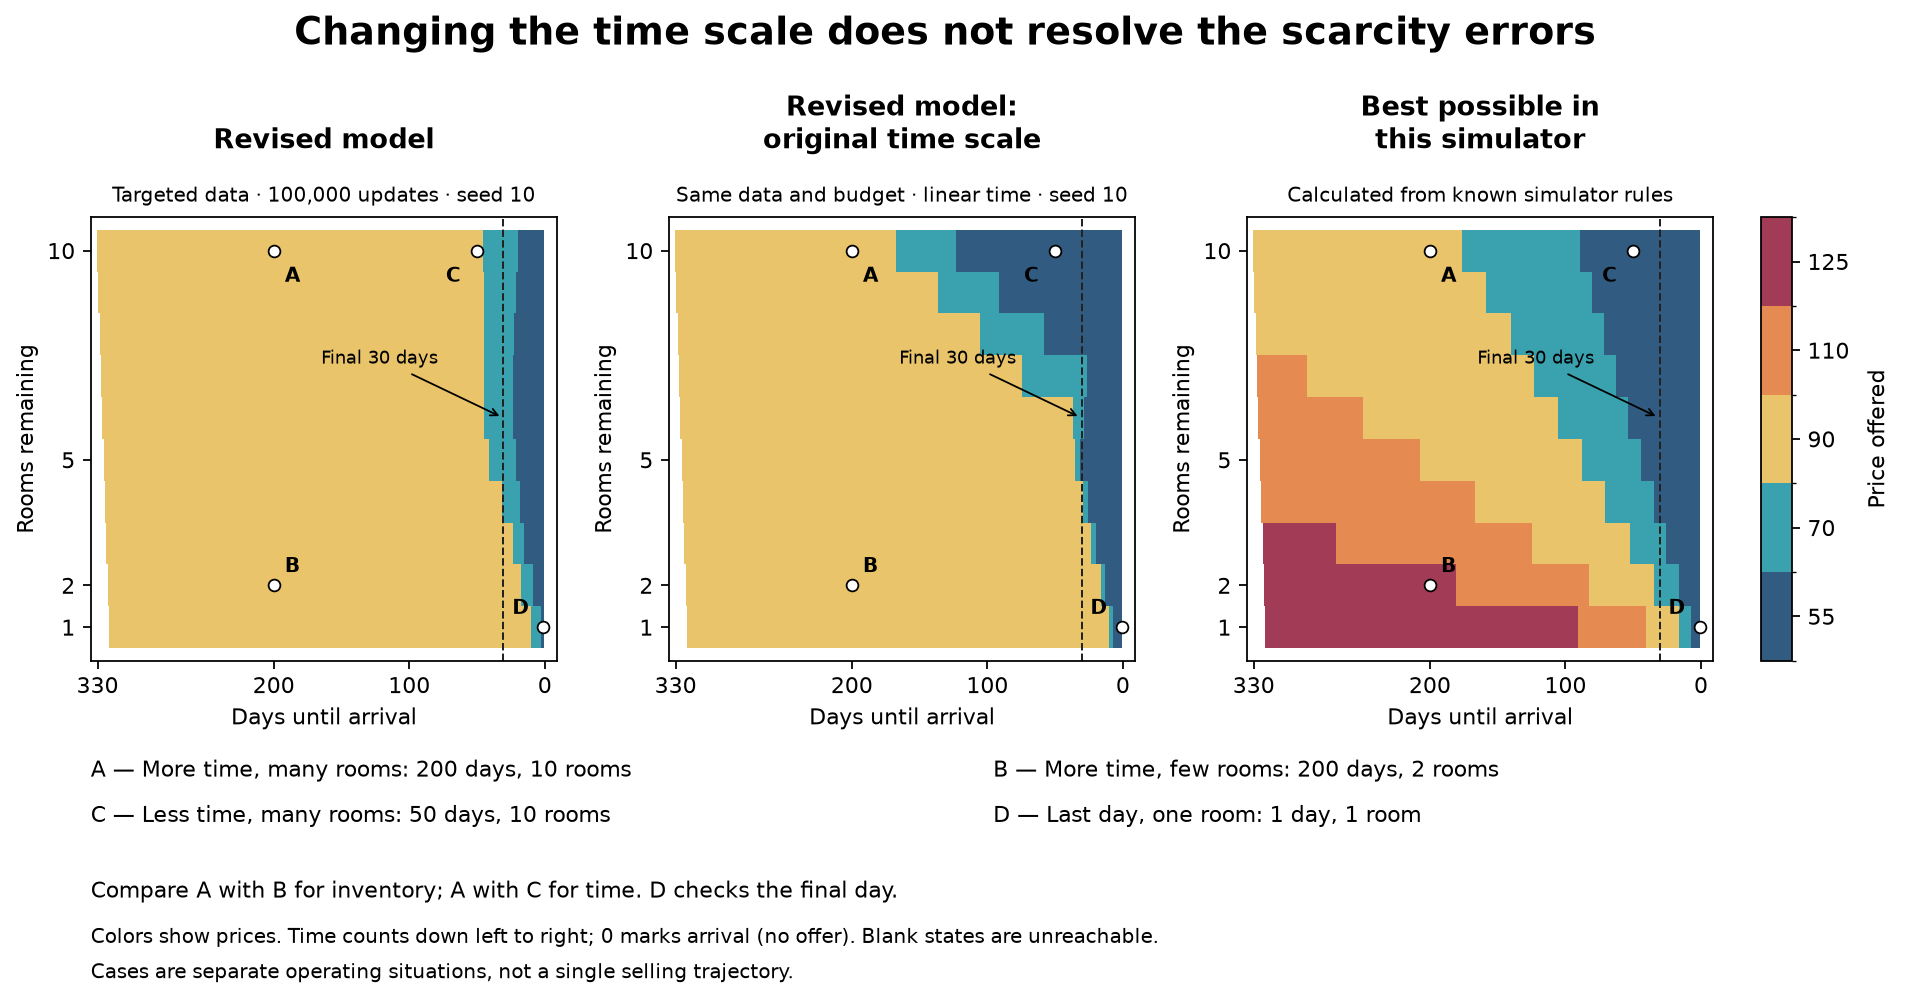

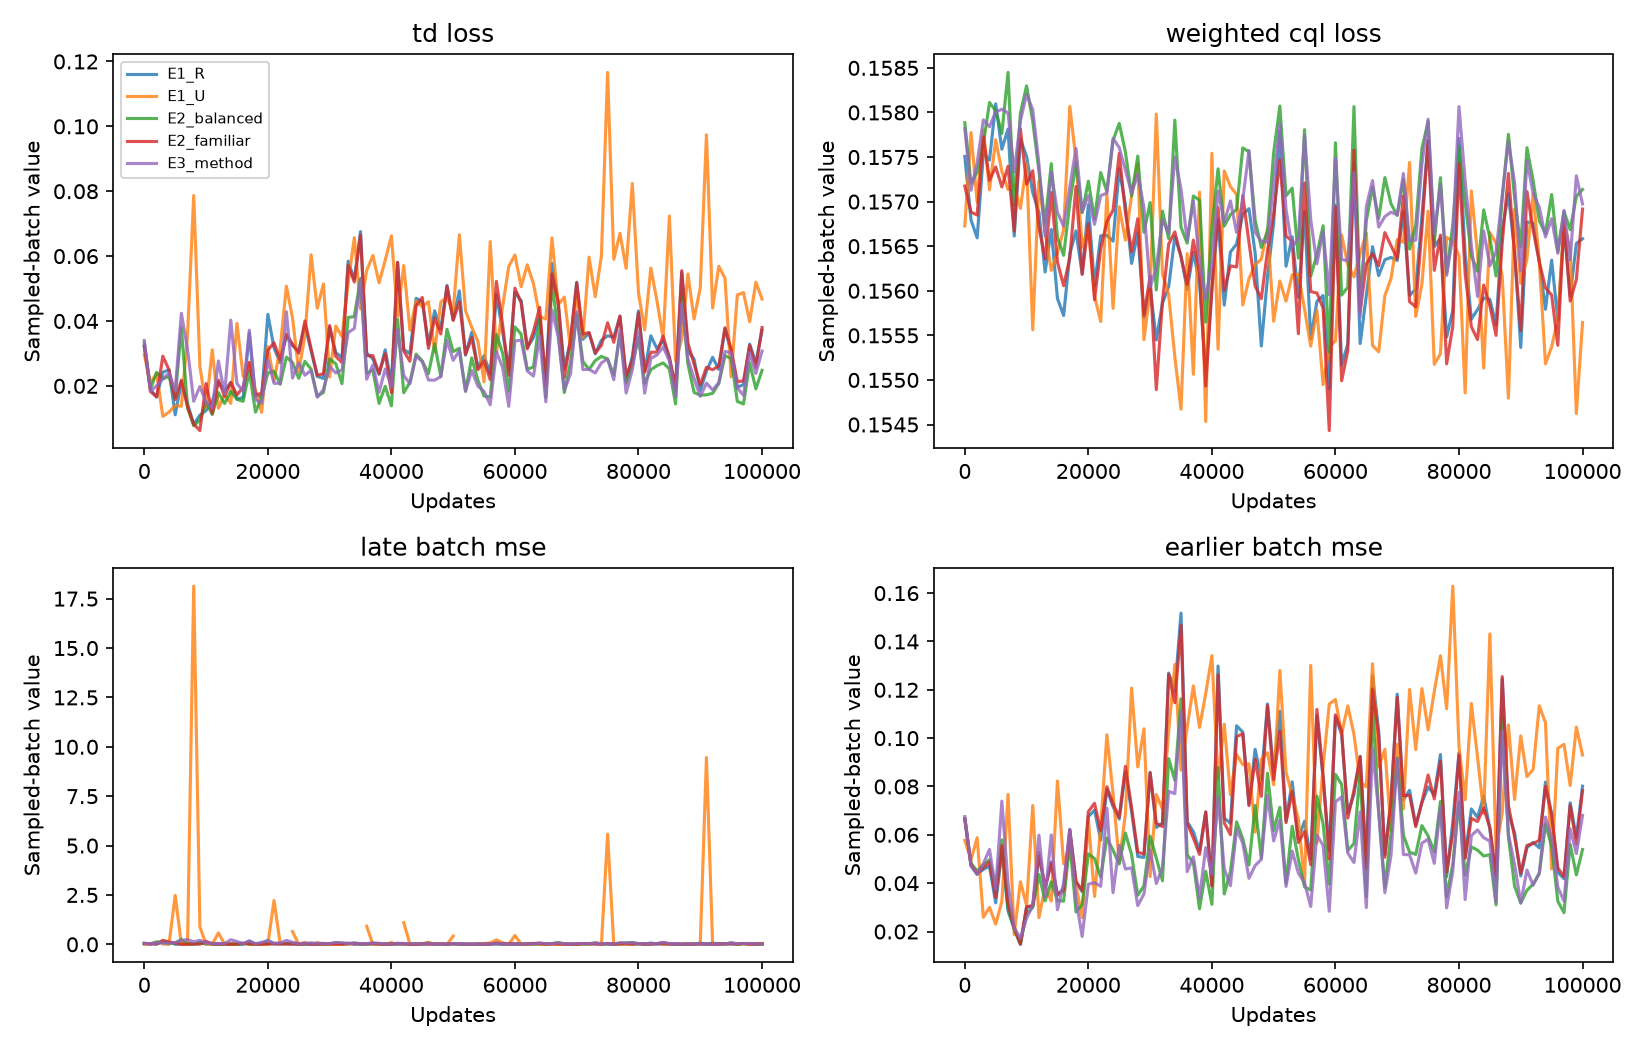

,arm,source,distinct_pairs,rows,sales
0,familiar,original,602,2766,141
1,familiar,added,602,150000,7355
2,familiar,combined,602,152766,7496
3,balanced,original,602,2766,141
4,balanced,added,1500,150000,8689
5,balanced,combined,1500,152766,8830


In [11]:
display(results[['experiment_id','seed','exact_revenue','primary_reference_id','minus_primary','matched_reference_id','minus_matched','gap_recovery']])
final_figure('policy_maps_time_control')
figure('learning_curves')
support=[]
for label in ['familiar','balanced']:
    folder=ROOT/'data/simulated/policy_improvement/probes'/label
    manifest=json.loads(required(folder/'manifest.json').read_text())
    support.extend([{'arm':label,**row} for row in manifest['support']])
display(pd.DataFrame(support))

## Appendix B. How do regional results vary by seed?

The main-text table averages three confirmation seeds. Here each endpoint retains its common-reference regional values alongside actual total regret, which equals its full-period gap to the simulator optimum. These are different measures.


In [12]:
display(confirmation[['experiment_id','seed','late_common_regret','earlier_common_regret','actual_total_regret']])

,experiment_id,seed,late_common_regret,earlier_common_regret,actual_total_regret
0,CONF_C100,10,2.697451,19.198491,22.042959
1,CONF_C100,11,0.835063,17.392153,18.604611
2,CONF_C100,12,10.575765,19.890191,31.176348
3,CONF_L100,10,1.375570,18.977860,20.652996
4,CONF_L100,11,0.898433,17.679135,19.165697
5,CONF_L100,12,7.782982,19.467448,27.381250
6,CONF_U100,10,17.433160,19.972071,37.406373
7,CONF_U20,10,17.434874,19.972397,37.407271
8,CONF_U100,11,17.434874,19.972397,37.407271
9,CONF_U20,11,17.434874,19.972397,37.407271


## Appendix C. Are the values and explanations accurate?

The same six cases and 64 reference states are used for each model. Each input transformation is applied once. The full tables also retain the alternative-reference sensitivity check.

Q scores use revenue divided by 90. The bound count checks upper bounds only. Zero violations do not establish accurate values. Negative values remain visible and, alone, do not prove an implementation bug.

The supported terminal fit used 10,000 training outcomes and 2,000 evaluation outcomes per price. The direct fit and noisier minibatch fit are separate checks.


In [13]:
terminal=confirmation[['experiment_id','seed']].reset_index(drop=True).copy()
terminal[['Q55','Q70','Q90','Q110','Q125']]=pd.DataFrame(confirmation.terminal_q.tolist())
terminal['upper_bound_violations_only']=confirmation.terminal_bound_violations.to_numpy()
display(terminal)
for seed in [10,11,12]:
    display(cases[(cases.seed==seed)&(cases.contrast=='55-90')][['configuration','days','rooms','selected_price','margin','reference_base','time_contribution','inventory_contribution']])
display(pd.DataFrame([{'penalty_weight':p['alpha'],'deterministic_error':p['deterministic_max_error'],'minibatch_error':p['minibatch_max_error']} for p in positive]))
display(pd.read_csv(required(OUT/'diagnostics/fresh_original_group_residuals.csv')))
print('Both margins and reference sensitivity: docs/policy_improvement/evidence/confirmation_cases.csv')

,experiment_id,seed,Q55,Q70,Q90,Q110,Q125,upper_bound_violations_only
0,CONF_C100,10,-0.194797,-0.201700,-0.249166,-0.251513,-0.219899,0
1,CONF_C100,11,-0.098648,-0.149876,-0.216007,-0.207968,-0.208307,0
2,CONF_C100,12,-0.176924,-0.152616,-0.144395,-0.192341,-0.189822,0
3,CONF_L100,10,-0.214589,-0.228289,-0.248765,-0.272710,-0.245284,0
4,CONF_L100,11,0.004549,-0.029667,-0.024965,-0.070845,-0.083153,0
5,CONF_L100,12,-0.106460,-0.092508,-0.115742,-0.123769,-0.135995,0
6,CONF_U100,10,0.406018,0.529206,0.623552,0.551798,0.514633,0
7,CONF_U20,10,1.233587,1.385926,1.541507,1.465815,1.419356,5
8,CONF_U100,11,1.247381,1.370280,1.529515,1.428295,1.391191,5
9,CONF_U20,11,0.648212,0.775897,0.908548,0.853673,0.777378,1


,configuration,days,rooms,selected_price,margin,reference_base,time_contribution,inventory_contribution
0,Revised model,200,2,90,-0.326754,-0.267099,0.001772,-0.061427
1,Revised model,200,10,90,-0.204374,-0.267099,0.003453,0.059272
2,Revised model,50,10,90,-0.006992,-0.267099,0.201716,0.058392
3,Revised model,1,1,55,0.054369,-0.267099,0.370878,-0.049411
4,Revised model,128,1,90,-0.283190,-0.267099,0.059604,-0.075695
5,Revised model,321,10,90,-0.271479,-0.267099,-0.063340,0.058960
36,Revised model: original time scale,200,2,90,-0.336765,-0.282530,0.009871,-0.064106
37,Revised model: original time scale,200,10,90,-0.083350,-0.282530,0.036216,0.162964
38,Revised model: original time scale,50,10,55,0.064219,-0.282530,0.212241,0.134508
39,Revised model: original time scale,1,1,55,0.034175,-0.282530,0.356077,-0.039371


,configuration,days,rooms,selected_price,margin,reference_base,time_contribution,inventory_contribution
12,Revised model,200,2,90,-0.293029,-0.252407,0.003204,-0.043826
13,Revised model,200,10,90,-0.176714,-0.252407,0.007211,0.068482
14,Revised model,50,10,55,0.041211,-0.252407,0.223979,0.069639
15,Revised model,1,1,55,0.117360,-0.252407,0.379682,-0.009915
16,Revised model,128,1,90,-0.272322,-0.252407,0.049822,-0.069737
17,Revised model,321,10,90,-0.257061,-0.252407,-0.061554,0.056900
48,Revised model: original time scale,200,2,90,-0.311284,-0.241120,-0.007125,-0.063039
49,Revised model: original time scale,200,10,90,-0.111930,-0.241120,0.011598,0.117592
50,Revised model: original time scale,50,10,55,0.089436,-0.241120,0.233305,0.097250
51,Revised model: original time scale,1,1,55,0.029513,-0.241120,0.321835,-0.051201


,configuration,days,rooms,selected_price,margin,reference_base,time_contribution,inventory_contribution
24,Revised model,200,2,90,-0.383311,-0.306373,0.002603,-0.079541
25,Revised model,200,10,90,-0.184124,-0.306373,0.009298,0.112950
26,Revised model,50,10,70,-0.050330,-0.306373,0.165708,0.090335
27,Revised model,1,1,90,-0.032529,-0.306373,0.322159,-0.048315
28,Revised model,128,1,90,-0.357564,-0.306373,0.052694,-0.103885
29,Revised model,321,10,90,-0.264635,-0.306373,-0.058086,0.099824
60,Revised model: original time scale,200,2,90,-0.379252,-0.304361,0.011034,-0.085925
61,Revised model: original time scale,200,10,90,-0.152735,-0.304361,0.026575,0.125052
62,Revised model: original time scale,50,10,70,-0.077370,-0.304361,0.135962,0.091029
63,Revised model: original time scale,1,1,70,0.009281,-0.304361,0.363564,-0.049921


,penalty_weight,deterministic_error,minibatch_error
0,0.0,3.894238e-08,0.008485
1,0.1,1.406177e-08,0.010143


,group,action,price,records,distinct_pairs,sales,no_sales,predicted_q,reward_scaled,bootstrap,td_target,signed_residual,squared_residual,weighted_cql,td_loss,bound_violations
0,t1,0,55,8,3,3,5,3.402736,0.229167,0.000000,0.229167,3.173570,12.658876,0.176809,6.329438,8
1,t1,1,70,8,5,1,7,4.325601,0.097222,0.000000,0.097222,4.228379,24.450483,0.164911,12.225242,8
2,t1,2,90,33,4,2,31,2.829020,0.060606,0.000000,0.060606,2.768414,11.128035,0.149175,5.564017,33
3,t1,3,110,7,3,0,7,3.011190,0.000000,0.000000,0.000000,3.011190,12.265577,0.155551,6.132789,7
4,t1,4,125,10,4,0,10,3.084744,0.000000,0.000000,0.000000,3.084744,13.866510,0.159763,6.933255,10
5,t2_7,0,55,38,15,5,33,2.603356,0.080409,2.650398,2.730808,-0.127452,0.169734,0.177464,0.084867,16
6,t2_7,1,70,61,20,5,56,2.992309,0.063752,2.985505,3.049257,-0.056948,0.113230,0.165239,0.056615,61
7,t2_7,2,90,213,29,9,204,3.307241,0.042254,3.225924,3.268178,0.039064,0.026879,0.149219,0.013440,213
8,t2_7,3,110,63,24,1,62,3.537483,0.019400,3.567971,3.587371,-0.049888,0.004907,0.155733,0.002454,63
9,t2_7,4,125,59,21,3,56,3.174784,0.070621,3.164836,3.235458,-0.060674,0.031235,0.159765,0.015617,59


Both margins and reference sensitivity: docs/policy_improvement/evidence/confirmation_cases.csv


## Appendix D. Which other situations change the recommendation?

A counterfactual comparison finds a nearby reachable state where the full five-price choice changes. The future-only version also requires time and inventory to move forward feasibly. No solution remains a valid answer.

Fresh paired rollouts are repeated simulated selling periods using matched random outcomes. Their intervals describe sampling noise for fixed policies. Exact evaluation remains the primary revenue measure.


In [14]:
display(deadline[['configuration','seed','selected_price','operating_condition','future_only']])
display(pd.DataFrame(read('paired_rollouts.json')))
display(pd.Series(read('report_verification.json')))
print('Viewing and reproduction: README.md')

,configuration,seed,selected_price,operating_condition,future_only
3,Revised model,10,55,"{'state': [3, 1], 'price': 70.0, 'delta_days': 2, 'delta_rooms': 0, 'distance': 0.006060606060606061, 'mode': 'operating_condition'}",None
15,Revised model,11,55,"{'state': [17, 1], 'price': 90.0, 'delta_days': 16, 'delta_rooms': 0, 'distance': 0.048484848484848485, 'mode': 'operating_condition'}",None
27,Revised model,12,90,"{'state': [3, 2], 'price': 70.0, 'delta_days': 2, 'delta_rooms': 1, 'distance': 0.10606060606060606, 'mode': 'operating_condition'}",None
39,Revised model: original time scale,10,55,"{'state': [8, 1], 'price': 70.0, 'delta_days': 7, 'delta_rooms': 0, 'distance': 0.021212121212121213, 'mode': 'operating_condition'}",None
51,Revised model: original time scale,11,55,"{'state': [15, 1], 'price': 90.0, 'delta_days': 14, 'delta_rooms': 0, 'distance': 0.04242424242424243, 'mode': 'operating_condition'}",None
63,Revised model: original time scale,12,70,"{'state': [9, 1], 'price': 90.0, 'delta_days': 8, 'delta_rooms': 0, 'distance': 0.024242424242424242, 'mode': 'operating_condition'}",None
75,Baseline with longer training,10,90,"{'state': [1, 9], 'price': 55.0, 'delta_days': 0, 'delta_rooms': 8, 'distance': 0.8, 'mode': 'operating_condition'}",None
87,Baseline model,10,90,None,None
99,Baseline with longer training,11,90,None,None
111,Baseline model,11,90,None,None


,run,reference,episodes,comparison,exact_difference,mean,ci95_half_width
0,CONF_C_10_100000,CONF_U20,1000,primary,15.364312,13.400,2.674773
1,CONF_C_10_100000,CONF_L100,1000,matched,-1.389963,-0.740,0.975285
2,CONF_C_11_100000,CONF_U20,1000,primary,18.802660,15.590,3.232736
3,CONF_C_11_100000,CONF_L100,1000,matched,0.561086,1.450,1.042548
4,CONF_C_12_100000,CONF_U20,1000,primary,6.230923,4.260,1.387319
5,CONF_C_12_100000,CONF_L100,1000,matched,-3.795098,-4.975,1.530287
6,CONF_L_10_100000,CONF_U20,1000,primary,16.754275,14.140,2.763077
7,CONF_L_10_100000,CONF_U100,1000,matched,16.753376,14.140,2.763077
8,CONF_L_11_100000,CONF_U20,1000,primary,18.241574,14.140,3.230837
9,CONF_L_11_100000,CONF_U100,1000,matched,18.241574,14.140,3.230837


historical_files_unchanged                                                                 104
models_reported                                                                             26
reference_cases                   [[200, 2], [200, 10], [50, 10], [1, 1], [128, 1], [321, 10]]
max_attribution_error                                                                      0.0
report_source_sha256          817a741f51bc015b59fefd5aec697bf8535f1d3bdc2819e55b4b05a4523e5365
dtype: object

Viewing and reproduction: README.md
